# 🌦️ La práctica de APIs — pídele el clima a la nube

> 📽 *Vienes de las láminas API-01 y API-02: el restaurante, los verbos y las llaves.*

Hoy tu código hace su **primera petición a un servidor**: el archivo climático de
[Open-Meteo](https://open-meteo.com), una cocina **pública** (no pide gafete) que sirve el
clima histórico de cualquier punto del planeta. El plan: **pedir → mirar → guardar →
commit**. El platillo de hoy es el insumo de la próxima clase.

In [1]:
# ✅ Punto de control · el entorno
try:
    import requests, pandas as pd
    print("✅ Entorno listo · requests", requests.__version__, "· pandas", pd.__version__)
except ImportError as e:
    print("⏳ Falta un paquete:", e)
    print("   ¿Creaste el entorno con requirements.txt? ¿Elegiste el kernel .venv (Select Kernel)?")

✅ Entorno listo · requests 2.34.2 · pandas 2.3.3


## 1 · La orden 🤵

Del menú de Open-Meteo pedimos el *endpoint* del archivo histórico. La orden lleva
**parámetros**: dónde (latitud/longitud), cuándo, y qué variables diarias queremos.
Fíjate: es un **GET** — solo leemos, no cambiamos nada en la cocina.

In [2]:
import requests

URL = "https://archive-api.open-meteo.com/v1/archive"     # el endpoint del menú
PARAMS = {
    "latitude": 19.43, "longitude": -99.13,               # Ciudad de México
    "start_date": "2024-01-01", "end_date": "2025-12-31",
    "daily": ",".join([
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "precipitation_sum", "windspeed_10m_max", "shortwave_radiation_sum",
    ]),
    "timezone": "America/Mexico_City",
}

r = requests.get(URL, params=PARAMS, timeout=30)
print("status_code:", r.status_code)   # 🔮 DEBES VER: 200 (todo bien). 404 = platillo inexistente; 429 = demasiadas órdenes

status_code: 200


## 2 · El platillo 🍽️

La respuesta viene en **JSON** — que en Python es… ¡un diccionario! Ya sabes moverte ahí.
Explora antes de convertir: ¿qué llaves trae? ¿dónde están los datos de verdad?

In [3]:
data = r.json()
print("llaves de la respuesta:", list(data.keys()))
print("llaves de data['daily']:", list(data["daily"].keys()))
print("la cocina confirma el punto:", data["latitude"], data["longitude"])

llaves de la respuesta: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
llaves de data['daily']: ['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'windspeed_10m_max', 'shortwave_radiation_sum']
la cocina confirma el punto: 19.437609 -99.10715


## 3 · De JSON a tabla

Un diccionario de listas paralelas es exactamente lo que `pandas` sabe convertir en tabla.

In [4]:
import pandas as pd

df = pd.DataFrame(data["daily"]).rename(columns={"time": "fecha"})
print(df.shape)          # 🔮 DEBES VER: (731, 7) — dos años, día por día
df.head()

(731, 7)


,fecha,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,windspeed_10m_max,shortwave_radiation_sum
0,2024-01-01,22.3,5.8,13.6,0.0,16.2,20.02
1,2024-01-02,22.3,6.4,14.0,0.0,18.2,17.36
2,2024-01-03,24.0,9.3,15.0,0.0,24.6,19.39
3,2024-01-04,24.9,4.5,13.6,0.0,16.5,20.04
4,2024-01-05,23.2,4.9,13.5,0.0,19.7,19.97


## 4 · Una probadita (el EDA formal llega la próxima clase)

In [5]:
df["precipitation_sum"].describe()

count    731.000000
mean       3.631190
std        6.574316
min        0.000000
25%        0.000000
50%        0.100000
75%        4.600000
max       50.700000
Name: precipitation_sum, dtype: float64

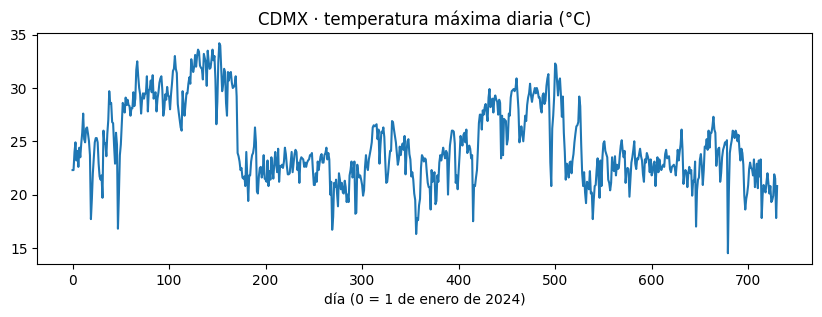

In [6]:
ax = df["temperature_2m_max"].plot(figsize=(10, 3), title="CDMX · temperatura máxima diaria (°C)")
ax.set_xlabel("día (0 = 1 de enero de 2024)");

## 5 · Guardar el platillo

El CSV se queda en tu repo: **la próxima clase lo metemos a una base de datos** y le
haremos preguntas en SQL.

In [7]:
df.to_csv("clima_cdmx.csv", index=False)
print("✅ clima_cdmx.csv guardado —", len(df), "días")

✅ clima_cdmx.csv guardado — 731 días


## 🧠 Mini Reto · otra cocina, mismo mesero

Pide el clima de **otra ciudad** (tu pueblo, una playa, un desierto — p. ej. Mérida:
`20.97, -89.62`) y guárdalo como `clima_otra.csv`. Solo cambian dos números de la orden.

In [10]:
import requests

URL = "https://archive-api.open-meteo.com/v1/archive"     # el endpoint del menú
PARAMS = {
    "latitude": 29.075, "longitude": -110.9583,               # Ciudad de México
    "start_date": "2024-01-01", "end_date": "2025-12-31",
    "daily": ",".join([
        "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
        "precipitation_sum", "windspeed_10m_max", "shortwave_radiation_sum",
    ]),
    "timezone": "America/Mexico_City",
}

r = requests.get(URL, params=PARAMS, timeout=30)
print("status_code:", r.status_code)   # 🔮 DEBES VER: 200 (todo bien). 404 = platillo inexistente; 429 = demasiadas órdenes

status_code: 200


In [11]:
data = r.json()
print("llaves de la respuesta:", list(data.keys()))
print("llaves de data['daily']:", list(data["daily"].keys()))
print("la cocina confirma el punto:", data["latitude"], data["longitude"])

llaves de la respuesta: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
llaves de data['daily']: ['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'windspeed_10m_max', 'shortwave_radiation_sum']
la cocina confirma el punto: 29.06854 -110.975876


In [12]:
import pandas as pd

df = pd.DataFrame(data["daily"]).rename(columns={"time": "fecha"})
print(df.shape)          # 🔮 DEBES VER: (731, 7) — dos años, día por día
df.head()

(731, 7)


,fecha,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,windspeed_10m_max,shortwave_radiation_sum
0,2024-01-01,21.9,8.2,14.9,0.0,18.0,14.18
1,2024-01-02,20.6,9.0,15.0,0.0,12.6,14.36
2,2024-01-03,22.4,7.7,14.8,0.0,13.4,14.70
3,2024-01-04,19.2,8.9,13.9,0.1,16.3,14.52
4,2024-01-05,20.0,8.7,13.3,0.0,15.7,14.90


In [13]:
df["precipitation_sum"].describe()

count    731.000000
mean       0.719425
std        4.523234
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max       67.700000
Name: precipitation_sum, dtype: float64

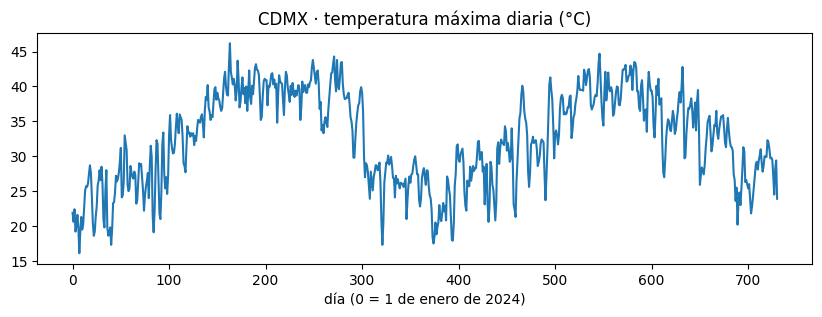

In [14]:
ax = df["temperature_2m_max"].plot(figsize=(10, 3), title="CDMX · temperatura máxima diaria (°C)")
ax.set_xlabel("día (0 = 1 de enero de 2024)");

## ▶ El cierre: que el tablero se entere

En la **terminal**, el ciclo de siempre — con la palabra mágica de Linear:

```
git add .
git commit -m "Fixes TAL-N: llegan los datos del clima"   ← usa el ID de TU issue
git push
```

**DEBES VER:** tu issue de Linear en **Done** sin que nadie lo tocara, y `clima_cdmx.csv`
en tu repo de GitHub. 🎉  *▶ Volvemos a las láminas para cerrar la clase.*